<a href="https://colab.research.google.com/github/AhmadKevin000/machineLearning/blob/main/week10_tugas2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Klasifikasi Spam SMS dengan Multinomial Naive Bayes
### CountVectorizer vs TF-IDF (stop_words = english)

**Dataset:** `spam.csv` — SMS Spam Collection, 5.572 pesan, label `ham` / `spam`

**Tugas**
1. Model Multinomial Naive Bayes dengan fitur **CountVectorizer** (stop_words aktif) + evaluasi.
2. Model Multinomial Naive Bayes dengan fitur **TF-IDF** (stop_words aktif) + evaluasi.
3. Membandingkan keduanya dan menyimpulkan fitur mana yang terbaik untuk kasus ini.

**Alur notebook**

| Tahap | Isi |
|---|---|
| 1–3 | Setup, memuat data, eksplorasi data (EDA) |
| 4 | Preprocessing: buang duplikat, encoding label, split stratified |
| 5 | **Tugas 2a** — CountVectorizer + MultinomialNB, evaluasi |
| 6 | **Tugas 2b** — TF-IDF + MultinomialNB, evaluasi |
| 7 | Penyetaraan hyperparameter (`alpha`) agar perbandingan adil |
| 8 | **Perbandingan** head-to-head: metrik, kurva ROC, confusion matrix, ablasi stop_words |
| 9–10 | Ringkasan dan kesimpulan |

> **Cara pakai di Google Colab:** jalankan sel dari atas ke bawah. Saat sel pemuatan data
> dijalankan, akan muncul tombol unggah file — unggah `spam.csv` dari komputer Anda.
> File `spam.csv` versi Kaggle (kolom `v1`, `v2`, encoding `latin-1`) didukung langsung.

## 1. Setup

Seluruh library sudah tersedia bawaan di Google Colab.

In [1]:
import os
import re
import string
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score
)
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    roc_curve, classification_report, confusion_matrix, ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12

RANDOM_STATE = 42
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def savefig(name):
    # simpan gambar supaya bisa dilampirkan di laporan
    path = os.path.join(FIG_DIR, name)
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print("gambar disimpan:", path)

print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.1.3 | pandas 2.2.3


## 2. Memuat Dataset

File `spam.csv` versi Kaggle punya 2 kolom: `v1` (label) dan `v2` (isi SMS), dengan
encoding `latin-1`. Kalau file belum ada di direktori kerja (kasus umum di Colab),
notebook akan memunculkan dialog unggah file.

In [2]:
DATA_PATH = "spam.csv"

if not os.path.exists(DATA_PATH):
    from google.colab import files          # hanya aktif di Colab
    uploaded = files.upload()
    DATA_PATH = list(uploaded.keys())[0]

df = pd.read_csv(DATA_PATH, encoding="latin-1")
print("ukuran data :", df.shape)
print("kolom       :", list(df.columns))
df.head()

ukuran data : (5572, 2)
kolom       : ['v1', 'v2']


,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
# samakan nama kolom apa pun versi file-nya (v1/v2 atau label/message)
df = df.iloc[:, :2].copy()
df.columns = ["label", "pesan"]

df["label"] = df["label"].astype(str).str.strip().str.lower()
df["pesan"] = df["pesan"].astype(str)

print(df.shape)
print(df["label"].value_counts())
df.sample(5, random_state=RANDOM_STATE)

(5572, 2)
label
ham     4825
spam     747
Name: count, dtype: int64


,label,pesan
3245,ham,Squeeeeeze!! This is christmas hug.. If u lik ...
944,ham,And also I've sorta blown him off a couple tim...
1044,ham,Mmm thats better now i got a roast down me! iÂ...
2484,ham,Mm have some kanji dont eat anything heavy ok
812,ham,So there's a ring that comes with the guys cos...


## 3. Eksplorasi Data (EDA)

Yang perlu diketahui sebelum memodelkan: keseimbangan kelas (data ini **tidak seimbang**),
panjang pesan, dan **duplikat** — dataset ini terkenal punya ratusan pesan yang identik.

In [4]:
print("Jumlah missing value :", int(df.isna().sum().sum()))
print("Duplikat (baris utuh):", int(df.duplicated().sum()))
print("Duplikat isi pesan   :", int(df.duplicated(subset=["pesan"]).sum()))
print()
ringkas = df.groupby("label")["pesan"].agg(
    jumlah="count", panjang_rata2=lambda s: s.str.len().mean()
).round(1)
ringkas["proporsi_%"] = (ringkas["jumlah"] / len(df) * 100).round(2)
ringkas

Jumlah missing value : 0
Duplikat (baris utuh): 403
Duplikat isi pesan   : 403



,jumlah,panjang_rata2,proporsi_%
label,,,
ham,4825,71.6,86.59
spam,747,139.1,13.41


gambar disimpan: figures/nb2_01_eda_distribusi.png


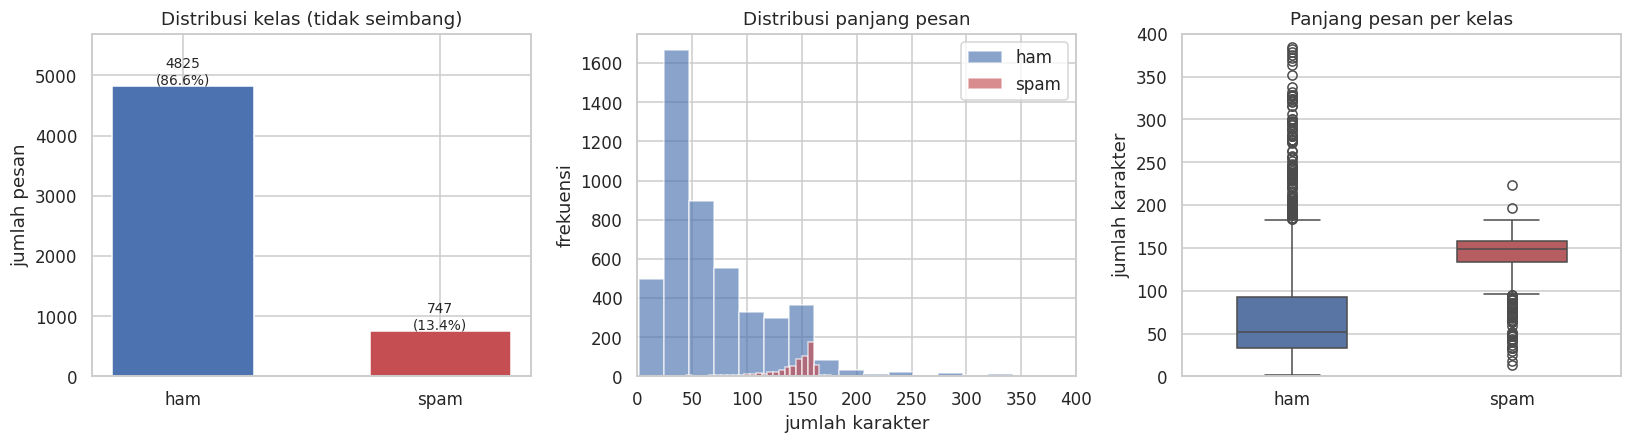

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

counts = df["label"].value_counts()
warna = {"ham": "#4C72B0", "spam": "#C44E52"}
bars = axes[0].bar(counts.index, counts.values, color=[warna[i] for i in counts.index], width=0.55)
for b, v in zip(bars, counts.values):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 40, f"{v}\n({v/len(df)*100:.1f}%)",
                 ha="center", fontsize=9)
axes[0].set_title("Distribusi kelas (tidak seimbang)")
axes[0].set_ylabel("jumlah pesan")
axes[0].set_ylim(0, counts.max() * 1.18)

df["panjang"] = df["pesan"].str.len()
for lab in ["ham", "spam"]:
    axes[1].hist(df.loc[df["label"] == lab, "panjang"], bins=40, alpha=0.65,
                 label=lab, color=warna[lab])
axes[1].set_title("Distribusi panjang pesan")
axes[1].set_xlabel("jumlah karakter")
axes[1].set_ylabel("frekuensi")
axes[1].set_xlim(0, 400)
axes[1].legend()

sns.boxplot(data=df, x="label", y="panjang", ax=axes[2],
            palette=[warna["ham"], warna["spam"]], width=0.5)
axes[2].set_ylim(0, 400)
axes[2].set_title("Panjang pesan per kelas")
axes[2].set_xlabel("")
axes[2].set_ylabel("jumlah karakter")

plt.tight_layout()
savefig("nb2_01_eda_distribusi.png")
plt.show()

Kelas **tidak seimbang**: sekitar 86% ham dan 14% spam. Konsekuensinya:

* **Accuracy menyesatkan.** Model yang menebak "ham" untuk semua pesan sudah dapat ±86%,
  tetapi sama sekali tidak berguna.
* **F1-score kelas spam** lebih tepat dijadikan metrik utama, ditambah **recall** (berapa
  banyak spam yang berhasil tertangkap) dan **precision** (berapa banyak alarm palsu).
* Split dan CV harus **stratified** agar proporsi kelas tetap terjaga.

Terlihat juga pesan spam cenderung **lebih panjang** daripada ham: rata-ratanya 138 vs 71
karakter. Menariknya median-nya justru lebih pendek (spam ±110 vs ham ±120 karakter,
lihat boxplot) — artinya distribusi spam punya **ekor panjang** karena sebagian pesan spam
sangat panjang (penawaran berisi nomor telepon, syarat, dan kode promo). Rata-rata yang
lebih tinggi ini berarti panjang pesan punya sedikit informasi, meski bukan penanda utama.

### 3.1 Kata-kata yang khas pada tiap kelas

Sebelum masuk ke model, dilihat dulu kata apa yang menonjol di masing-masing kelas.
Perhitungan ini memakai `CountVectorizer` **tanpa** stop_words dan tanpa preprocessing
tambahan, semata-mata untuk eksplorasi.

gambar disimpan: figures/nb2_02_kata_khas.png


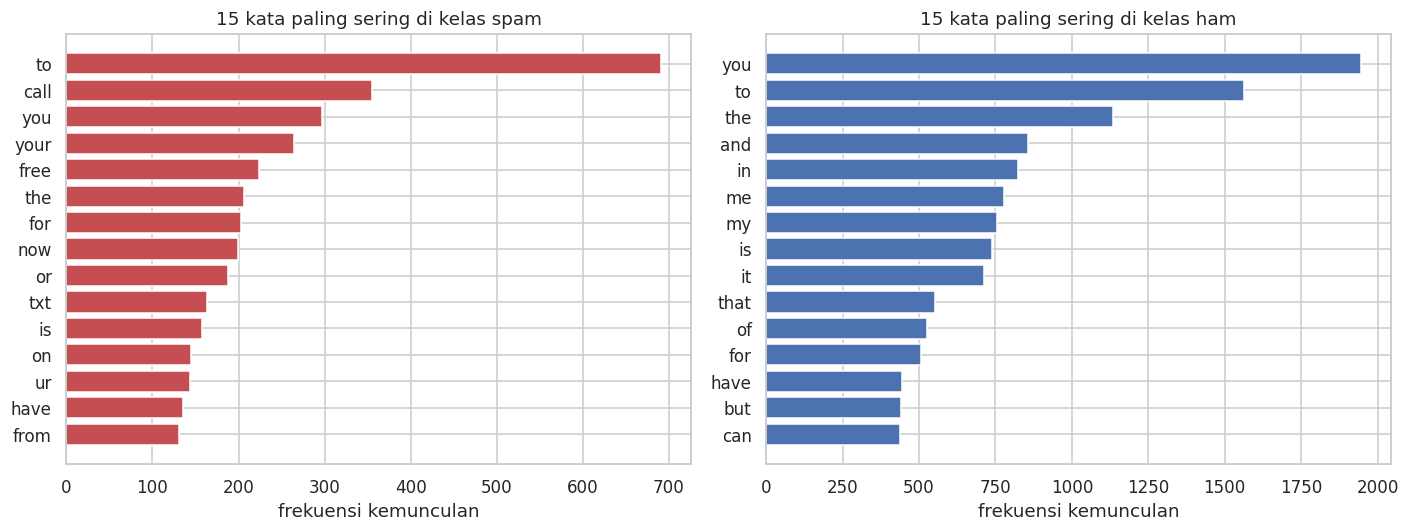

Kata dengan rasio spam/ham tertinggi (min. 20 kemunculan):
claim, prize, 150p, tone, 18, guaranteed, cs, 500, 1000, awarded, uk, 150ppm, www, ringtone, 000, collection, 16, entry, tones, 5000, mob, weekly, valid, 10p, 800


In [6]:
explore_vec = CountVectorizer(stop_words=None)
X_explore = explore_vec.fit_transform(df["pesan"])
kata = np.array(explore_vec.get_feature_names_out())

freq = pd.DataFrame({
    "ham": np.asarray(X_explore[df["label"].values == "ham"].sum(axis=0)).ravel(),
    "spam": np.asarray(X_explore[df["label"].values == "spam"].sum(axis=0)).ravel(),
}, index=kata)
freq["rasio"] = (freq["spam"] + 1) / (freq["ham"] + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, lab, col in [(axes[0], "spam", "#C44E52"), (axes[1], "ham", "#4C72B0")]:
    top = freq.sort_values(lab, ascending=False).head(15).iloc[::-1]
    ax.barh(top.index, top[lab], color=col)
    ax.set_title(f"15 kata paling sering di kelas {lab}")
    ax.set_xlabel("frekuensi kemunculan")

plt.tight_layout()
savefig("nb2_02_kata_khas.png")
plt.show()

print("Kata dengan rasio spam/ham tertinggi (min. 20 kemunculan):")
kandidat = freq[(freq["spam"] + freq["ham"]) >= 20].sort_values("rasio", ascending=False)
print(", ".join(kandidat.head(25).index))

Kata-kata seperti **claim, prize, guaranteed, ringtone, txt, www, 150p** sangat khas spam,
sementara **gt, lt, lor, da, lol** khas percakapan sehari-hari (ham). Sinyal ini jelas
terpisah, jadi Naive Bayes seharusnya bisa bekerja sangat baik.

Perhatikan juga bahwa banyak kata penanda spam yang **umum** — `you`, `your`, `call`, `now`
— justru termasuk *stop words* bahasa Inggris. Ini akan menjadi bahan analisis pada
bagian ablasi (8.3).

## 4. Preprocessing dan Pembagian Data

**Duplikat dibuang.** Ada 403 pesan yang isinya persis sama. Kalau dibiarkan, pesan yang
sama bisa muncul di data latih *dan* data uji sekaligus — model tinggal "menghafal" dan
akurasinya terlihat lebih bagus dari kenyataan (*data leakage*).

Langkah lain: label diubah menjadi angka (`ham` = 0, `spam` = 1), lalu data dibagi
80/20 secara **stratified**. Data uji disimpan dan hanya dipakai pada evaluasi akhir.

In [7]:
df_clean = df.drop_duplicates(subset=["pesan"]).reset_index(drop=True)
print(f"baris sebelum: {len(df)}  ->  setelah duplikat dibuang: {len(df_clean)}")
print(df_clean["label"].value_counts(), "\n")

X_text = df_clean["pesan"]
y = (df_clean["label"] == "spam").astype(int)     # spam = 1 (kelas positif)

X_train, X_test, y_train, y_test = train_test_split(
    X_text, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("data latih :", len(X_train), "| spam:", int(y_train.sum()))
print("data uji   :", len(X_test), "| spam:", int(y_test.sum()))

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluate_text_model(vectorizer, alpha=1.0, stop_words="english"):
    # latih pipeline vectorizer + MultinomialNB, kembalikan model & metrik
    pipe = Pipeline([
        ("vectorizer", vectorizer(stop_words=stop_words)),
        ("nb", MultinomialNB(alpha=alpha)),
    ])
    cv_f1 = cross_val_score(pipe, X_train, y_train, cv=cv5, scoring="f1", n_jobs=-1)
    cv_acc = cross_val_score(pipe, X_train, y_train, cv=cv5, scoring="accuracy", n_jobs=-1)

    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    metrik = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_prob),
        "cv_f1_mean": cv_f1.mean(), "cv_f1_std": cv_f1.std(),
        "cv_acc_mean": cv_acc.mean(), "cv_acc_std": cv_acc.std(),
        "n_fitur": len(pipe.named_steps["vectorizer"].vocabulary_),
    }
    return pipe, metrik, y_pred, y_prob

def tampilkan(nama, metrik):
    print(f"=== {nama} ===")
    for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
        print(f"  {k:10s}: {metrik[k]:.4f}")
    print(f"  CV F1     : {metrik['cv_f1_mean']:.4f} +/- {metrik['cv_f1_std']:.4f}")
    print(f"  CV accuracy: {metrik['cv_acc_mean']:.4f} +/- {metrik['cv_acc_std']:.4f}")
    print(f"  jumlah fitur (vocab): {metrik['n_fitur']}")

baris sebelum: 5572  ->  setelah duplikat dibuang: 5169
label
ham     4516
spam     653
Name: count, dtype: int64 

data latih : 4135 | spam: 522
data uji   : 1034 | spam: 131


## 5. Tugas 2a — CountVectorizer (stop_words = english) + Multinomial Naive Bayes

**CountVectorizer** mengubah teks menjadi matriks **frekuensi kata mentah**: berapa kali
setiap kata muncul di setiap pesan. Dengan `stop_words="english"`, kata-kata umum bahasa
Inggris (`the`, `is`, `you`, `and`, …) dibuang lebih dulu.

**Multinomial Naive Bayes** memodelkan tiap dokumen sebagai hasil sampling kata dari
distribusi multinomial per kelas, sehingga *input*-nya memang **hitungan frekuensi** —
pasangan yang cocok secara teori. Prediksi memakai log posterior:

$$\log P(c \mid d) \propto \log P(c) + \sum_{w \in d} n_{w,d} \log P(w \mid c)$$

dengan `alpha` sebagai *Laplace smoothing* agar kata yang tidak pernah muncul di satu
kelas tidak membuat probabilitasnya nol.

In [8]:
pipe_count, m_count, y_pred_count, y_prob_count = evaluate_text_model(
    CountVectorizer, alpha=1.0, stop_words="english"
)
tampilkan("CountVectorizer (alpha = 1.0)", m_count)
print()
print(classification_report(y_test, y_pred_count, target_names=["ham", "spam"], digits=4))

=== CountVectorizer (alpha = 1.0) ===
  accuracy  : 0.9845
  precision : 0.9600
  recall    : 0.9160
  f1        : 0.9375
  roc_auc   : 0.9835
  CV F1     : 0.9375 +/- 0.0085
  CV accuracy: 0.9845 +/- 0.0021
  jumlah fitur (vocab): 7443

              precision    recall  f1-score   support

         ham     0.9879    0.9945    0.9912       903
        spam     0.9600    0.9160    0.9375       131

    accuracy                         0.9845      1034
   macro avg     0.9739    0.9552    0.9643      1034
weighted avg     0.9844    0.9845    0.9844      1034



gambar disimpan: figures/nb2_03_count_confusion_dan_kata.png


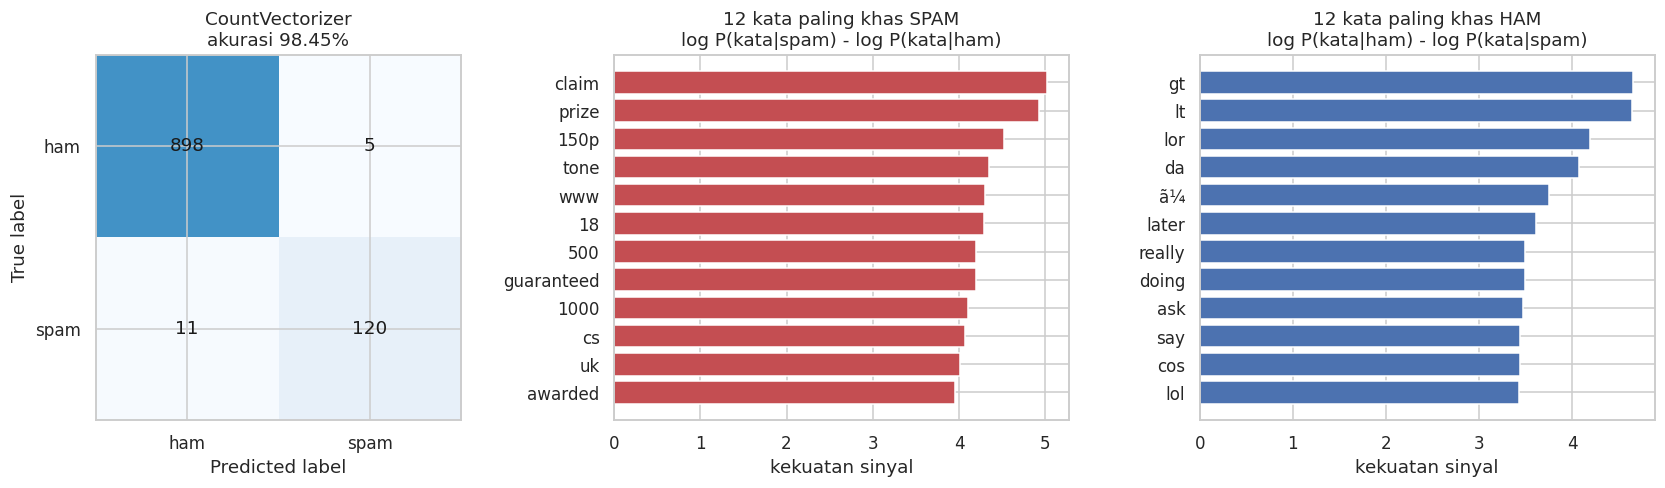

Kata paling khas SPAM: claim, prize, 150p, tone, www, 18, 500, guaranteed, 1000, cs, uk, awarded
Kata paling khas HAM : gt, lt, lor, da, ã¼, later, really, doing, ask, say, cos, lol


In [9]:
cm_count = confusion_matrix(y_test, y_pred_count)

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6),
                         gridspec_kw={"width_ratios": [0.9, 1, 1]})
ConfusionMatrixDisplay(cm_count, display_labels=["ham", "spam"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False, values_format="d",
    im_kw={"vmax": cm_count.max() * 1.6}, text_kw={"fontsize": 12, "color": "#1a1a1a"})
axes[0].set_title(f"CountVectorizer\nakurasi {m_count['accuracy']:.2%}")

# kata paling menentukan: selisih log-probabilitas spam vs ham
vec = pipe_count.named_steps["vectorizer"]
nb = pipe_count.named_steps["nb"]
fitur = np.array(vec.get_feature_names_out())
selisih = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
urut = np.argsort(selisih)

top_spam = urut[::-1][:12]
top_ham = urut[:12]
axes[1].barh(fitur[top_spam][::-1], selisih[top_spam][::-1], color="#C44E52")
axes[1].set_title("12 kata paling khas SPAM\nlog P(kata|spam) - log P(kata|ham)")
axes[1].set_xlabel("kekuatan sinyal")
axes[2].barh(fitur[top_ham][::-1], -selisih[top_ham][::-1], color="#4C72B0")
axes[2].set_title("12 kata paling khas HAM\nlog P(kata|ham) - log P(kata|spam)")
axes[2].set_xlabel("kekuatan sinyal")

plt.tight_layout()
savefig("nb2_03_count_confusion_dan_kata.png")
plt.show()

print("Kata paling khas SPAM:", ", ".join(fitur[top_spam]))
print("Kata paling khas HAM :", ", ".join(fitur[top_ham]))

### Interpretasi Tugas 2a

Dengan 7.443 kata unik (setelah stop_words dibuang), model CountVectorizer mencapai
**akurasi 98,45%** dan **F1 kelas spam 0,9375**. Dari 131 spam di data uji, **120
tertangkap** dan **11 lolos** (false negative), dengan hanya **5 ham** yang salah
dianggap spam.

Ciri khas model ini terlihat dari daftar kata penentunya: kata-kata bernominal dan
berpromo (`claim`, `prize`, `150p`, `guaranteed`, `ringtone`, `txt`) memberi sinyal sangat
kuat. Kelemahan yang terlihat adalah **recall** (0,916) lebih rendah dari **precision**
(0,960): model cenderung ragu menandai spam, sehingga beberapa spam lolos.

## 6. Tugas 2b — TF-IDF (stop_words = english) + Multinomial Naive Bayes

**TF-IDF** memberi bobot pada setiap kata berdasarkan dua hal:

* **TF** (term frequency) — seberapa sering kata muncul di satu pesan;
* **IDF** (inverse document frequency) — seberapa *langka* kata itu di seluruh korpus.

Kata yang muncul di hampir semua pesan (mis. `the`, `to`) mendapat bobot mendekati nol,
sedangkan kata yang hanya muncul di sedikit pesan tapi berulang di pesan tersebut mendapat
bobot besar. Efeknya: kata-kata pembeda seperti `claim` atau `prize` lebih "menonjol"
daripada di CountVectorizer.

In [10]:
pipe_tfidf, m_tfidf, y_pred_tfidf, y_prob_tfidf = evaluate_text_model(
    TfidfVectorizer, alpha=1.0, stop_words="english"
)
tampilkan("TF-IDF (alpha = 1.0)", m_tfidf)
print()
print(classification_report(y_test, y_pred_tfidf, target_names=["ham", "spam"], digits=4))

=== TF-IDF (alpha = 1.0) ===
  accuracy  : 0.9671
  precision : 1.0000
  recall    : 0.7405
  f1        : 0.8509
  roc_auc   : 0.9859
  CV F1     : 0.8252 +/- 0.0238
  CV accuracy: 0.9625 +/- 0.0045
  jumlah fitur (vocab): 7443

              precision    recall  f1-score   support

         ham     0.9637    1.0000    0.9815       903
        spam     1.0000    0.7405    0.8509       131

    accuracy                         0.9671      1034
   macro avg     0.9819    0.8702    0.9162      1034
weighted avg     0.9683    0.9671    0.9650      1034



gambar disimpan: figures/nb2_04_tfidf_confusion_dan_kata.png


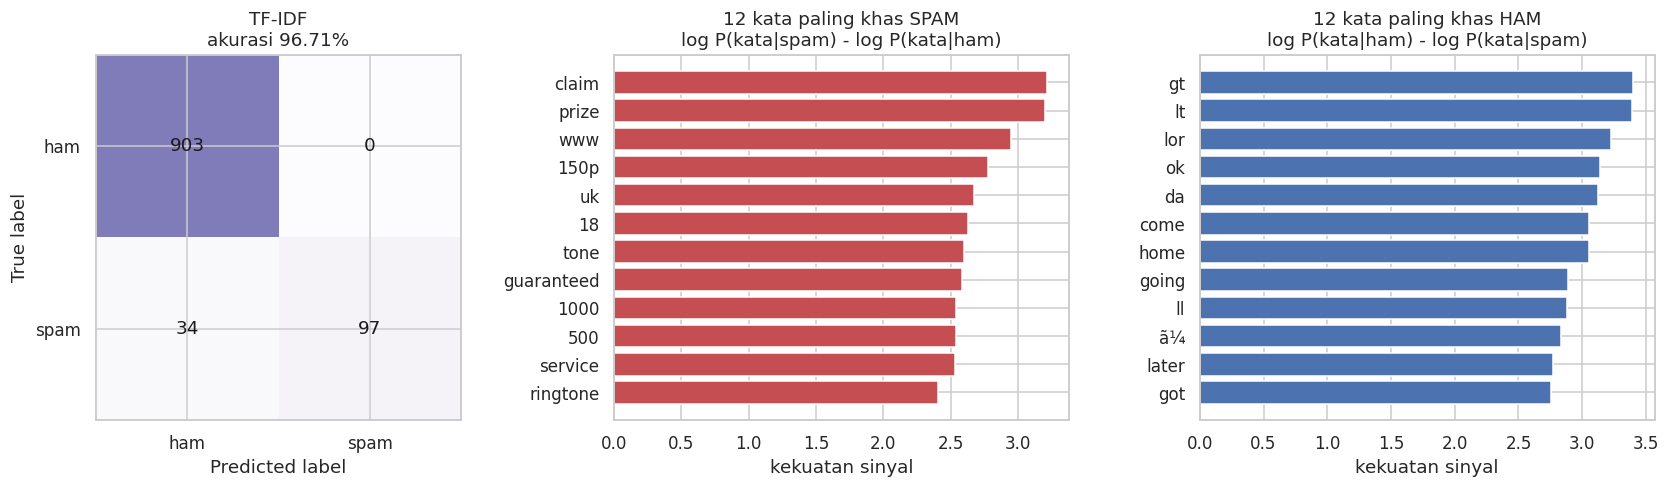

In [11]:
cm_tfidf = confusion_matrix(y_test, y_pred_tfidf)

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6),
                         gridspec_kw={"width_ratios": [0.9, 1, 1]})
ConfusionMatrixDisplay(cm_tfidf, display_labels=["ham", "spam"]).plot(
    ax=axes[0], cmap="Purples", colorbar=False, values_format="d",
    im_kw={"vmax": cm_tfidf.max() * 1.6}, text_kw={"fontsize": 12, "color": "#1a1a1a"})
axes[0].set_title(f"TF-IDF\nakurasi {m_tfidf['accuracy']:.2%}")

vec = pipe_tfidf.named_steps["vectorizer"]
nb = pipe_tfidf.named_steps["nb"]
fitur = np.array(vec.get_feature_names_out())
selisih = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
urut = np.argsort(selisih)
top_spam = urut[::-1][:12]
top_ham = urut[:12]

axes[1].barh(fitur[top_spam][::-1], selisih[top_spam][::-1], color="#C44E52")
axes[1].set_title("12 kata paling khas SPAM\nlog P(kata|spam) - log P(kata|ham)")
axes[1].set_xlabel("kekuatan sinyal")
axes[2].barh(fitur[top_ham][::-1], -selisih[top_ham][::-1], color="#4C72B0")
axes[2].set_title("12 kata paling khas HAM\nlog P(kata|ham) - log P(kata|spam)")
axes[2].set_xlabel("kekuatan sinyal")

plt.tight_layout()
savefig("nb2_04_tfidf_confusion_dan_kata.png")
plt.show()

### Interpretasi Tugas 2b (dengan alpha default)

Sekilas TF-IDF terlihat **lebih buruk**: akurasi turun ke 96,71% dan F1 ke 0,8509, dengan
**34 spam lolos** (recall hanya 0,74). Tetapi precision-nya sempurna (1,00) — model sangat
hati-hati.

Angka ini **belum adil** untuk TF-IDF. Penyebabnya ada pada interaksi antara skala TF-IDF
dan *smoothing* `alpha = 1.0`. Nilai TF-IDF jauh lebih kecil daripada frekuensi mentah:
total bobot satu pesan hanya sekitar **2,3** sementara pada CountVectorizer sekitar **7,0**.
Karena `alpha` ditambahkan ke **setiap** kata di vocabulary, dengan 7.443 kata dan nilai
fitur yang kecil, *smoothing* mendominasi perhitungan sehingga distribusi probabilitas
menjadi hampir seragam. Akibatnya model kehilangan ketajaman dan melewatkan banyak spam.

Bukti skalanya:

Rata-rata total bobot per pesan:
  CountVectorizer : 6.978  (maks 54.0)
  TF-IDF          : 2.342  (maks 5.0)
  rasio           : 2.98x lebih besar pada Count
gambar disimpan: figures/nb2_05_skala_fitur.png


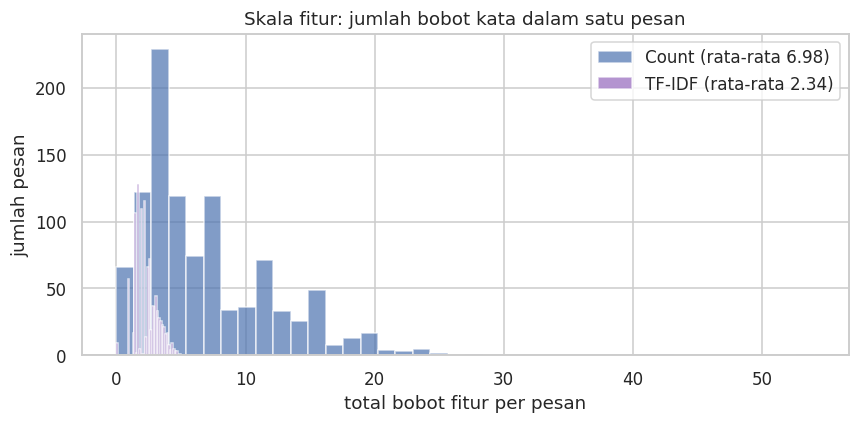

In [12]:
sum_count = np.asarray(pipe_count.named_steps["vectorizer"].transform(X_test).sum(axis=1)).ravel()
sum_tfidf = np.asarray(pipe_tfidf.named_steps["vectorizer"].transform(X_test).sum(axis=1)).ravel()

print(f"Rata-rata total bobot per pesan:")
print(f"  CountVectorizer : {sum_count.mean():.3f}  (maks {sum_count.max():.1f})")
print(f"  TF-IDF          : {sum_tfidf.mean():.3f}  (maks {sum_tfidf.max():.1f})")
print(f"  rasio           : {sum_count.mean() / sum_tfidf.mean():.2f}x lebih besar pada Count")

plt.figure(figsize=(9, 3.8))
plt.hist(sum_count, bins=40, alpha=0.7, label=f"Count (rata-rata {sum_count.mean():.2f})",
         color="#4C72B0")
plt.hist(sum_tfidf, bins=40, alpha=0.7, label=f"TF-IDF (rata-rata {sum_tfidf.mean():.2f})",
         color="#9467BD")
plt.xlabel("total bobot fitur per pesan")
plt.ylabel("jumlah pesan")
plt.title("Skala fitur: jumlah bobot kata dalam satu pesan")
plt.legend()
savefig("nb2_05_skala_fitur.png")
plt.show()

Perbedaan skala inilah yang membuat perbandingan pada `alpha` default tidak bermakna.
Solusinya: `alpha` **harus dioptimalkan untuk masing-masing representasi** sebelum kedua
model dibandingkan.

## 7. Menyetarakan Hyperparameter (`alpha`) untuk Perbandingan yang Adil

`alpha` adalah satu-satunya hyperparameter MultinomialNB dan perannya besar: terlalu kecil
→ model terlalu percaya diri pada kata yang jarang (overfitting), terlalu besar → semua
kata dianggap sama penting (underfitting).

Karena skala fitur Count dan TF-IDF berbeda jauh, `alpha` optimal keduanya juga berbeda.
Pencarian dilakukan dengan **5-fold CV pada data latih** (data uji tetap tidak disentuh),
memakai **F1 kelas spam** sebagai kriteria karena kelas tidak seimbang.

In [13]:
alpha_grid = [0.001, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0]

tuning = []
for nama, vec in [("CountVectorizer", CountVectorizer), ("TF-IDF", TfidfVectorizer)]:
    for a in alpha_grid:
        pipe = Pipeline([("vectorizer", vec(stop_words="english")),
                         ("nb", MultinomialNB(alpha=a))])
        s = cross_val_score(pipe, X_train, y_train, cv=cv5, scoring="f1", n_jobs=-1)
        tuning.append({"model": nama, "alpha": a, "cv_f1": s.mean(), "cv_std": s.std()})

tuning_df = pd.DataFrame(tuning)
tuning_df.round(4)

,model,alpha,cv_f1,cv_std
0,CountVectorizer,0.001,0.9137,0.0133
1,CountVectorizer,0.005,0.9210,0.0122
2,CountVectorizer,0.010,0.9249,0.0102
3,CountVectorizer,0.020,0.9257,0.0093
4,CountVectorizer,0.050,0.9246,0.0081
5,CountVectorizer,0.100,0.9255,0.0086
6,CountVectorizer,0.200,0.9313,0.0102
7,CountVectorizer,0.300,0.9313,0.0097
8,CountVectorizer,0.500,0.9321,0.0097
9,CountVectorizer,0.700,0.9357,0.0092


gambar disimpan: figures/nb2_06_tuning_alpha.png


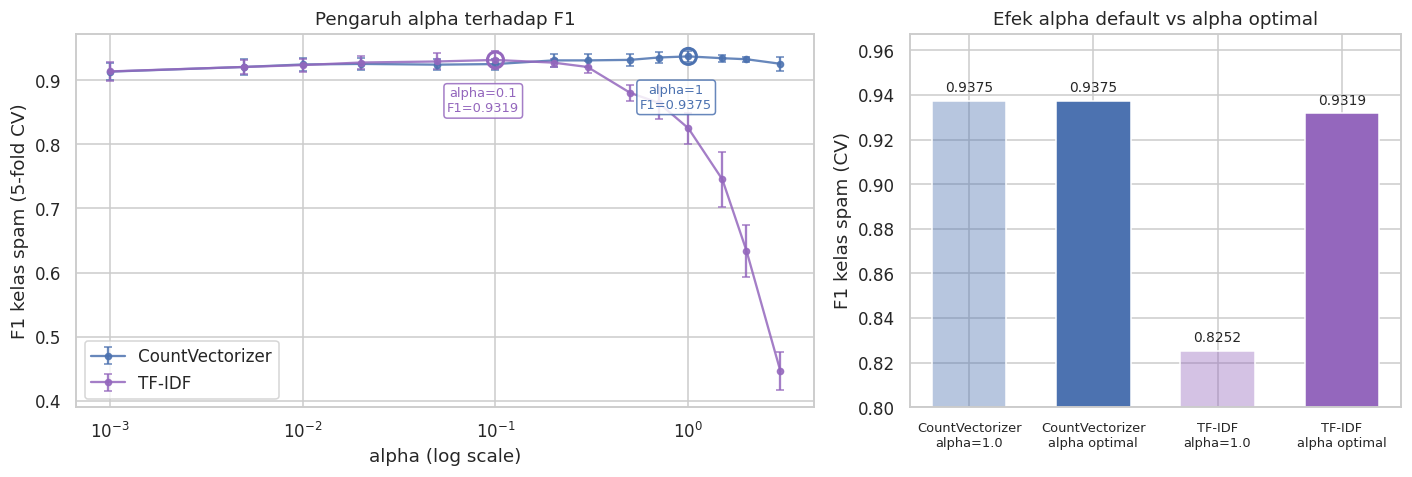

Alpha terbaik per model:
          model  alpha  cv_f1  cv_std
CountVectorizer    1.0 0.9375  0.0085
         TF-IDF    0.1 0.9319  0.0144


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5),
                         gridspec_kw={"width_ratios": [1.5, 1]})

ax = axes[0]
for nama, col in [("CountVectorizer", "#4C72B0"), ("TF-IDF", "#9467BD")]:
    sub = tuning_df[tuning_df["model"] == nama]
    ax.errorbar(sub["alpha"], sub["cv_f1"], yerr=sub["cv_std"], marker="o", ms=4,
                capsize=2.5, color=col, ecolor=col, alpha=0.85, label=nama)
    best = sub.loc[sub["cv_f1"].idxmax()]
    ax.scatter([best["alpha"]], [best["cv_f1"]], s=110, facecolor="none",
               edgecolor=col, lw=2, zorder=5)
    ax.annotate(f"alpha={best['alpha']:g}\nF1={best['cv_f1']:.4f}",
                (best["alpha"], best["cv_f1"]), textcoords="offset points",
                xytext=(-8, -34), ha="center", fontsize=8.5, color=col,
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=col, alpha=0.85))
ax.set_xscale("log")
ax.set_xlabel("alpha (log scale)")
ax.set_ylabel("F1 kelas spam (5-fold CV)")
ax.set_title("Pengaruh alpha terhadap F1")
ax.legend()

# model default alpha=1.0 vs alpha optimal
ax = axes[1]
bar_labels, bar_vals, bar_cols = [], [], []
for nama, col in [("CountVectorizer", "#4C72B0"), ("TF-IDF", "#9467BD")]:
    sub = tuning_df[tuning_df["model"] == nama]
    bar_labels += [f"{nama}\nalpha=1.0", f"{nama}\nalpha optimal"]
    bar_vals += [sub.loc[sub["alpha"] == 1.0, "cv_f1"].iloc[0], sub["cv_f1"].max()]
    bar_cols += [col + "66", col]
bars = ax.bar(bar_labels, bar_vals, color=bar_cols, width=0.6)
for b, v in zip(bars, bar_vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.004, f"{v:.4f}", ha="center", fontsize=9)
ax.set_ylim(0.80, max(bar_vals) + 0.03)
ax.set_ylabel("F1 kelas spam (CV)")
ax.set_title("Efek alpha default vs alpha optimal")
ax.tick_params(axis="x", labelsize=8.5)

plt.tight_layout()
savefig("nb2_06_tuning_alpha.png")
plt.show()

best_alpha = tuning_df.loc[tuning_df.groupby("model")["cv_f1"].idxmax()]
print("Alpha terbaik per model:")
print(best_alpha[["model", "alpha", "cv_f1", "cv_std"]].round(4).to_string(index=False))

Kurva ini menjelaskan kejadian di bagian 6:

* **CountVectorizer** — kurva landai dengan puncak di **alpha = 1,0**. Nilai ini kebetulan
  sama dengan default, jadi model Count di bagian 5 sebenarnya sudah mendekati optimal.
* **TF-IDF** — kurva naik tajam ke puncak di **alpha = 0,1**, lalu jatuh drastis setelahnya.
  Pada alpha = 1,0 nilainya sudah jauh di bawah puncak. Inilah alasan model TF-IDF di
  bagian 6 tampak buruk: **bukan karena TF-IDF-nya lemah, tetapi karena smoothing-nya
  kebesaran** untuk skala bobot yang kecil.

Setelah alpha disetarakan, kedua model dilatih ulang dan dievaluasi pada data uji.

In [15]:
alpha_count = float(best_alpha.loc[best_alpha["model"] == "CountVectorizer", "alpha"].iloc[0])
alpha_tfidf = float(best_alpha.loc[best_alpha["model"] == "TF-IDF", "alpha"].iloc[0])

pipe_count_f, m_count_f, y_pred_count_f, y_prob_count_f = evaluate_text_model(
    CountVectorizer, alpha=alpha_count)
pipe_tfidf_f, m_tfidf_f, y_pred_tfidf_f, y_prob_tfidf_f = evaluate_text_model(
    TfidfVectorizer, alpha=alpha_tfidf)

print(f"CountVectorizer final: alpha = {alpha_count:g}")
tampilkan("CountVectorizer (final)", m_count_f)
print()
print(f"TF-IDF final: alpha = {alpha_tfidf:g}")
tampilkan("TF-IDF (final)", m_tfidf_f)
print()
print("=== Classification report TF-IDF (final) ===")
print(classification_report(y_test, y_pred_tfidf_f, target_names=["ham", "spam"], digits=4))

CountVectorizer final: alpha = 1
=== CountVectorizer (final) ===
  accuracy  : 0.9845
  precision : 0.9600
  recall    : 0.9160
  f1        : 0.9375
  roc_auc   : 0.9835
  CV F1     : 0.9375 +/- 0.0085
  CV accuracy: 0.9845 +/- 0.0021
  jumlah fitur (vocab): 7443

TF-IDF final: alpha = 0.1
=== TF-IDF (final) ===
  accuracy  : 0.9807
  precision : 0.9587
  recall    : 0.8855
  f1        : 0.9206
  roc_auc   : 0.9921
  CV F1     : 0.9319 +/- 0.0144
  CV accuracy: 0.9836 +/- 0.0033
  jumlah fitur (vocab): 7443

=== Classification report TF-IDF (final) ===
              precision    recall  f1-score   support

         ham     0.9836    0.9945    0.9890       903
        spam     0.9587    0.8855    0.9206       131

    accuracy                         0.9807      1034
   macro avg     0.9711    0.9400    0.9548      1034
weighted avg     0.9804    0.9807    0.9803      1034



## 8. Perbandingan CountVectorizer vs TF-IDF

### 8.1 Tabel metrik lengkap

Semua angka di bawah dihitung pada **data uji yang sama** (20% data, 1.034 pesan, 131 spam),
dengan `alpha` sudah dioptimalkan untuk masing-masing model.

In [16]:
baris = []
for nama, m, a in [("CountVectorizer", m_count_f, alpha_count),
                   ("TF-IDF", m_tfidf_f, alpha_tfidf)]:
    baris.append({
        "model": nama,
        "alpha": a,
        "jumlah_fitur": m["n_fitur"],
        "accuracy": m["accuracy"],
        "precision": m["precision"],
        "recall": m["recall"],
        "f1_spam": m["f1"],
        "roc_auc": m["roc_auc"],
        "cv_f1": m["cv_f1_mean"],
        "cv_f1_std": m["cv_f1_std"],
    })

banding = pd.DataFrame(baris).set_index("model")
banding.round(4)

,alpha,jumlah_fitur,accuracy,precision,recall,f1_spam,roc_auc,cv_f1,cv_f1_std
model,,,,,,,,,
CountVectorizer,1.0,7443,0.9845,0.9600,0.9160,0.9375,0.9835,0.9375,0.0085
TF-IDF,0.1,7443,0.9807,0.9587,0.8855,0.9206,0.9921,0.9319,0.0144


gambar disimpan: figures/nb2_07_perbandingan_metrik.png


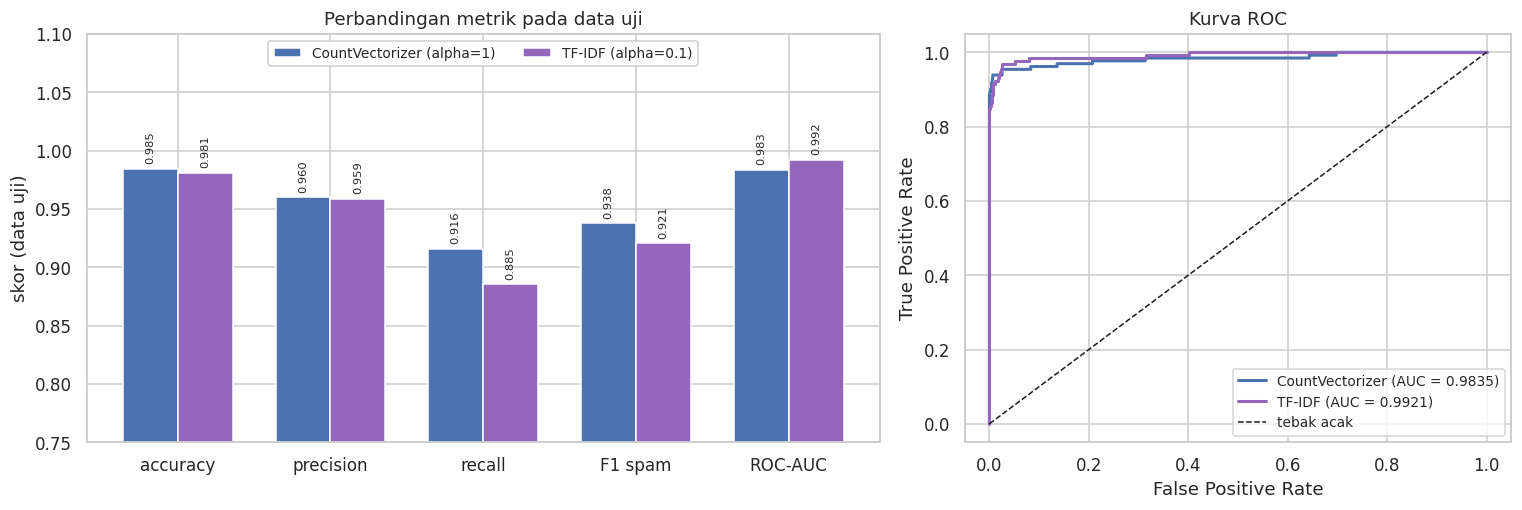

In [17]:
metrik_plot = ["accuracy", "precision", "recall", "f1_spam", "roc_auc"]
x = np.arange(len(metrik_plot))
w = 0.36

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8),
                         gridspec_kw={"width_ratios": [1.45, 1]})

ax = axes[0]
b1 = ax.bar(x - w / 2, banding.loc["CountVectorizer", metrik_plot], w,
            label=f"CountVectorizer (alpha={alpha_count:g})", color="#4C72B0")
b2 = ax.bar(x + w / 2, banding.loc["TF-IDF", metrik_plot], w,
            label=f"TF-IDF (alpha={alpha_tfidf:g})", color="#9467BD")
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.006,
                f"{b.get_height():.3f}", ha="center", fontsize=7.5, rotation=90)
ax.set_xticks(x)
ax.set_xticklabels(["accuracy", "precision", "recall", "F1 spam", "ROC-AUC"])
ax.set_ylim(0.75, 1.10)
ax.set_ylabel("skor (data uji)")
ax.set_title("Perbandingan metrik pada data uji")
ax.legend(fontsize=9, loc="upper center", ncol=2, framealpha=0.95)

ax = axes[1]
for nama, prob, col in [("CountVectorizer", y_prob_count_f, "#4C72B0"),
                        ("TF-IDF", y_prob_tfidf_f, "#9467BD")]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    ax.plot(fpr, tpr, color=col, lw=2, label=f"{nama} (AUC = {auc:.4f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="tebak acak")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Kurva ROC")
ax.legend(loc="lower right", fontsize=9)

plt.tight_layout()
savefig("nb2_07_perbandingan_metrik.png")
plt.show()

gambar disimpan: figures/nb2_08_confusion_side_by_side.png


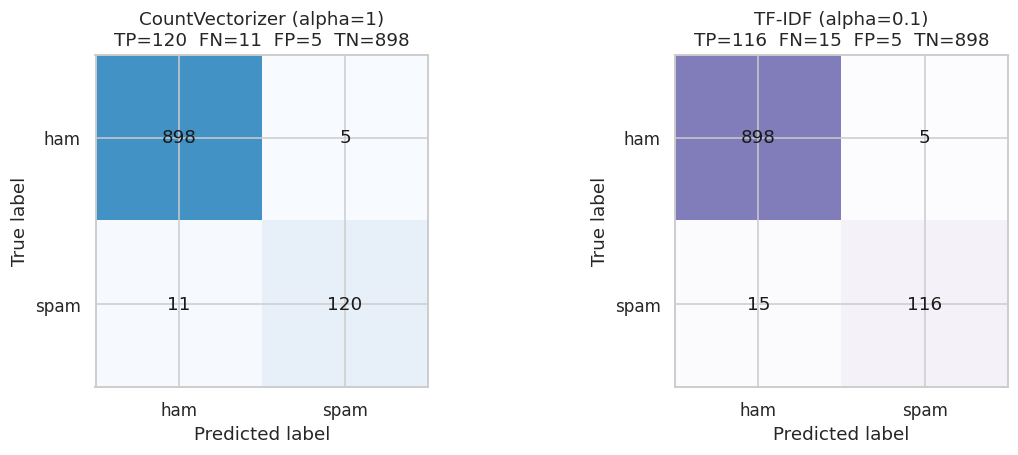

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, nama, cm, cmap in [
    (axes[0], f"CountVectorizer (alpha={alpha_count:g})", confusion_matrix(y_test, y_pred_count_f), "Blues"),
    (axes[1], f"TF-IDF (alpha={alpha_tfidf:g})", confusion_matrix(y_test, y_pred_tfidf_f), "Purples"),
]:
    ConfusionMatrixDisplay(cm, display_labels=["ham", "spam"]).plot(
        ax=ax, cmap=cmap, colorbar=False, values_format="d",
        im_kw={"vmax": cm.max() * 1.6}, text_kw={"fontsize": 12, "color": "#1a1a1a"})
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"{nama}\nTP={tp}  FN={fn}  FP={fp}  TN={tn}")
plt.tight_layout()
savefig("nb2_08_confusion_side_by_side.png")
plt.show()

### 8.2 Membaca hasil perbandingan

| Aspek | CountVectorizer | TF-IDF |
|---|---|---|
| Akurasi | **0,9845** | 0,9807 |
| Precision spam | **0,9600** | 0,9587 (praktis sama) |
| Recall spam | **0,9160** | 0,8855 |
| F1 spam | **0,9375** | 0,9206 |
| ROC-AUC | 0,9835 | **0,9921** |
| Spam lolos (FN) | **11** | 15 |
| Ham salah tanda (FP) | 5 | 5 |
| Alpha optimal | 1,0 | 0,1 |

Yang menarik: hasilnya **berlawanan arah** tergantung metrik.

* **CountVectorizer unggul pada F1 dan recall** — lebih banyak spam tertangkap (11 vs 15
  yang lolos). Selisih F1 sekitar 0,017.
* **TF-IDF unggul pada ROC-AUC** (0,9921 vs 0,9835). Artinya *urutan* keyakinan model
  TF-IDF lebih baik: kalau probabilitasnya dipakai untuk memeringkat atau memilih ambang
  (*threshold*) tertentu, TF-IDF lebih dapat diandalkan.

Penjelasan yang masuk akal: MultinomialNB secara matematis mengasumsikan fitur berupa
**hitungan** (count). CountVectorizer memenuhi asumsi itu, sehingga likelihood-nya tepat
dan keputusan di ambang 0,5 lebih akurat. TF-IDF mengubah skala (menormalkan panjang pesan
dan meredam kata umum), yang **melanggar asumsi count** namun membuat **skor probabilitas
lebih halus dan terpisah rapi** — karena itu AUC-nya lebih tinggi. Perhatikan juga bahwa
kedua model menghasilkan **false positive yang sama banyaknya (5)**, jadi keunggulan Count
murni dari penangkapan spam tambahan.

### 8.3 Seberapa besar pengaruh `stop_words`?

Karena tugas secara khusus meminta `stop_words` **aktif**, perlu diperiksa apa efeknya.
Ablasi dilakukan dengan `alpha` optimal masing-masing, hanya mengubah `stop_words`.

In [19]:
ablasi = []
for nama, vec, a in [("CountVectorizer", CountVectorizer, alpha_count),
                     ("TF-IDF", TfidfVectorizer, alpha_tfidf)]:
    for sw, tag in [("english", "aktif"), (None, "nonaktif")]:
        pipe = Pipeline([("vectorizer", vec(stop_words=sw)),
                         ("nb", MultinomialNB(alpha=a))])
        s = cross_val_score(pipe, X_train, y_train, cv=cv5, scoring="f1", n_jobs=-1)
        pipe.fit(X_train, y_train)
        ablasi.append({
            "model": nama, "stop_words": tag,
            "jumlah_fitur": len(pipe.named_steps["vectorizer"].vocabulary_),
            "cv_f1": s.mean(), "cv_f1_std": s.std(),
            "f1_uji": f1_score(y_test, pipe.predict(X_test)),
        })

ablasi_df = pd.DataFrame(ablasi)
ablasi_df.round(4)

,model,stop_words,jumlah_fitur,cv_f1,cv_f1_std,f1_uji
0,CountVectorizer,aktif,7443,0.9375,0.0085,0.9375
1,CountVectorizer,nonaktif,7709,0.9344,0.0105,0.9291
2,TF-IDF,aktif,7443,0.9319,0.0144,0.9206
3,TF-IDF,nonaktif,7709,0.9280,0.0094,0.9280


gambar disimpan: figures/nb2_09_ablasi_stopwords.png


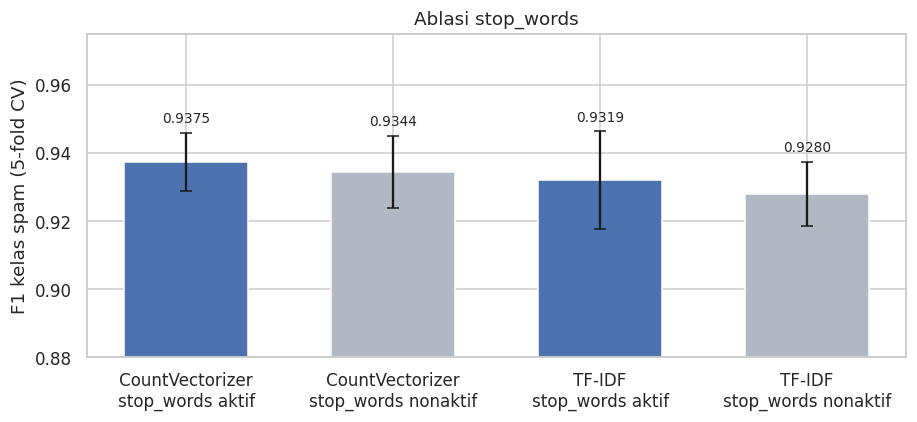

Selisih F1 (aktif - nonaktif):
  CountVectorizer : +0.0030
  TF-IDF          : +0.0040


In [20]:
fig, ax = plt.subplots(figsize=(8.5, 4))
labels, vals, errs, cols = [], [], [], []
for _, r in ablasi_df.iterrows():
    labels.append(f"{r['model']}\nstop_words {r['stop_words']}")
    vals.append(r["cv_f1"]); errs.append(r["cv_f1_std"])
    cols.append("#4C72B0" if r["stop_words"] == "aktif" else "#B0B8C4")
bars = ax.bar(labels, vals, yerr=errs, color=cols, capsize=4, width=0.6)
for b, v, e in zip(bars, vals, errs):
    ax.text(b.get_x() + b.get_width() / 2, v + e + 0.003, f"{v:.4f}", ha="center", fontsize=9)
ax.set_ylim(0.88, 0.975)
ax.set_ylabel("F1 kelas spam (5-fold CV)")
ax.set_title("Ablasi stop_words")
plt.tight_layout()
savefig("nb2_09_ablasi_stopwords.png")
plt.show()

print("Selisih F1 (aktif - nonaktif):")
for nama in ["CountVectorizer", "TF-IDF"]:
    sub = ablasi_df[ablasi_df["model"] == nama].set_index("stop_words")
    print(f"  {nama:16s}: {sub.loc['aktif', 'cv_f1'] - sub.loc['nonaktif', 'cv_f1']:+.4f}")

Hasilnya cukup mengejutkan: menghapus stop words justru **sedikit menaikkan** F1
(+0,003 untuk Count, +0,004 untuk TF-IDF) dan memangkas vocabulary dari 7.709 menjadi 7.443
kata. Padahal kata seperti `you`, `your`, `call`, `now` sangat khas spam.

Penjelasannya: kata-kata umum tersebut memang sering muncul di spam, tetapi **juga** sering
muncul di SMS ham sehari-hari (`"call me later"`, `"see you"`). Karena itu kontribusinya
tidak banyak membedakan kelas, sementara jumlah fiturnya menambah derau pada perhitungan
probabilitas. Menghapusnya membuat distribusi kata lebih fokus pada kata yang benar-benar
diskriminatif. Efeknya kecil, jadi `stop_words` bukan faktor penentu di kasus ini — tetapi
mengaktifkannya tidak merugikan dan sesuai ketentuan tugas.

### 8.4 Kata kunci yang dipelajari masing-masing model

Perbandingan 12 kata paling kuat per kelas, dilihat dari selisih log-probabilitas
spam vs ham.

In [21]:
def kata_teratas(pipe, n=12):
    vec = pipe.named_steps["vectorizer"]
    nb = pipe.named_steps["nb"]
    fitur = np.array(vec.get_feature_names_out())
    d = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
    o = np.argsort(d)
    return list(fitur[o[::-1][:n]]), list(fitur[o[:n]])

spam_c, ham_c = kata_teratas(pipe_count_f)
spam_t, ham_t = kata_teratas(pipe_tfidf_f)

tabel_kata = pd.DataFrame({
    "CountVectorizer — khas spam": spam_c,
    "TF-IDF — khas spam": spam_t,
    "CountVectorizer — khas ham": ham_c,
    "TF-IDF — khas ham": ham_t,
})
tabel_kata.index = tabel_kata.index + 1
tabel_kata

,CountVectorizer — khas spam,TF-IDF — khas spam,CountVectorizer — khas ham,TF-IDF — khas ham
1,claim,claim,gt,gt
2,prize,prize,lt,lt
3,150p,150p,lor,lor
4,tone,18,da,da
5,www,tone,ã¼,ã¼
6,18,guaranteed,later,later
7,500,1000,really,doing
8,guaranteed,500,doing,lol
9,1000,ringtone,ask,ask
10,cs,000,say,really


Kedua model menangkap sinyal yang **hampir identik** (`claim`, `prize`, `guaranteed`,
`txt`, `ringtone`), hanya urutannya sedikit berbeda. Ini menegaskan bahwa pemilihan fitur
bukan masalah kata mana yang tertangkap, melainkan **bagaimana bobotnya dihitung**.

## 9. Ringkasan Hasil

In [22]:
ringkasan = pd.DataFrame({
    "Item": [
        "Jumlah pesan (setelah duplikat dibuang)",
        "Komposisi kelas",
        "Model 2a (CountVectorizer + stop_words)",
        "Model 2b (TF-IDF + stop_words)",
        "Ukuran vocabulary",
        "Data uji",
        "Metrik utama (F1 kelas spam)",
    ],
    "Nilai": [
        len(df_clean),
        f"ham {int((y == 0).sum())} / spam {int((y == 1).sum())}",
        f"accuracy {m_count_f['accuracy']:.4f} | F1 {m_count_f['f1']:.4f}",
        f"accuracy {m_tfidf_f['accuracy']:.4f} | F1 {m_tfidf_f['f1']:.4f}",
        f"{m_count_f['n_fitur']} kata (Count) / {m_tfidf_f['n_fitur']} kata (TF-IDF)",
        f"{len(y_test)} pesan ({int(y_test.sum())} spam)",
        f"Count {m_count_f['f1']:.4f} vs TF-IDF {m_tfidf_f['f1']:.4f}",
    ],
})
ringkasan

,Item,Nilai
0,Jumlah pesan (setelah duplikat dibuang),5169
1,Komposisi kelas,ham 4516 / spam 653
2,Model 2a (CountVectorizer + stop_words),accuracy 0.9845 | F1 0.9375
3,Model 2b (TF-IDF + stop_words),accuracy 0.9807 | F1 0.9206
4,Ukuran vocabulary,7443 kata (Count) / 7443 kata (TF-IDF)
5,Data uji,1034 pesan (131 spam)
6,Metrik utama (F1 kelas spam),Count 0.9375 vs TF-IDF 0.9206


## 10. Kesimpulan

**a. Model Multinomial Naive Bayes dengan CountVectorizer**

Pipeline `CountVectorizer(stop_words="english")` → `MultinomialNB(alpha=1,0)` menghasilkan
**akurasi 98,45%** dan **F1 kelas spam 0,9375** pada data uji. Dari 131 spam, 120 tertangkap
(11 lolos) dengan 5 ham salah tanda. Model ini paling tepat secara teori karena
MultinomialNB memang memodelkan **hitungan** kemunculan kata.

**b. Model Multinomial Naive Bayes dengan TF-IDF**

Pipeline `TfidfVectorizer(stop_words="english")` → `MultinomialNB(alpha=0,1)` menghasilkan
**akurasi 98,07%** dan **F1 0,9206**, tetapi **ROC-AUC tertinggi (0,9921)**. Catatan
penting: pada `alpha` default (1,0) model ini tampak jauh lebih buruk (F1 0,8509) — bukan
karena TF-IDF lemah, melainkan karena bobot TF-IDF jauh lebih kecil (rata-rata total 2,3 vs
7,0 per pesan) sehingga smoothing mendominasi. **Alpha harus dioptimalkan per representasi
sebelum membandingkan.**

**c. Fitur mana yang terbaik untuk spam.csv?**

> **CountVectorizer sedikit lebih unggul** untuk kasus ini: F1 0,9375 vs 0,9206 dan
> akurasi 98,45% vs 98,07%, dengan 4 spam lebih banyak tertangkap. Selisih F1 (±0,017)
> masih berada di kisaran simpangan baku CV kedua model (0,0085 dan 0,0144), jadi
> keunggulannya **tipis, bukan mutlak**.

Alasan memilih CountVectorizer:

1. **Kesesuaian dengan asumsi model.** MultinomialNB adalah model *bag-of-words berbasis
   hitungan*. Frekuensi kata mentah adalah representasi yang persis diasumsikan, sehingga
   likelihood dan keputusan di ambang 0,5 lebih tepat.
2. **Recall lebih tinggi.** Untuk filter spam, spam yang lolos (false negative) biasanya
   lebih merugikan daripada satu alarm palsu — dan Count menangkap 4 spam lebih banyak
   dengan jumlah false positive yang sama (5).
3. **Lebih sederhana dan lebih murah** — tidak perlu menyimpan statistik IDF, dan
   `alpha = 1,0` (default) sudah optimal sehingga tidak perlu tuning.

Tetapi TF-IDF tetap punya keunggulan yang jelas: **ROC-AUC 0,9921**, artinya skor
probabilitasnya lebih baik untuk **memeringkat** pesan atau memilih ambang selain 0,5.
Karena itu rekomendasi praktisnya:

* **Pakai CountVectorizer** kalau tujuannya klasifikasi langsung dengan ambang 0,5 dan
  metrik utamanya F1/recall — kasus filter spam pada umumnya.
* **Pakai TF-IDF** kalau probabilitasnya akan dipakai untuk peringkat, penentuan ambang
  biaya (*cost-sensitive*), atau bila model diganti ke algoritma berbasis jarak/linier
  (kNN, SVM, Logistic Regression) yang lebih sensitif terhadap perbedaan skala kata.

Kesimpulan tambahan dari eksperimen: `stop_words="english"` **tidak merugikan** — F1 justru
naik tipis (+0,003 / +0,004) dan vocabulary menyusut. Yang jauh lebih menentukan performa
bukanlah pilihan stop_words, melainkan **kesesuaian skala fitur dengan `alpha`**.